# Confidence Intervals, Skewness, and Bootstrap

Gaussian confidence intervals, skewness calculations, simulation, and bootstrap intervals.

Originally developed for CSCI 443 at the University of Mississippi. Assignment prompts and provided teaching examples are course material; this notebook contains my submitted responses and code.

Saved outputs are retained from the uploaded coursework. This packaged copy has not been rerun end to end. See the repository README for required data and review notes.


**Important Note to Students:**

This homework is designed to help you develop intuition about confidence intervals, sampling distributions, and the behavior of statistical estimators with different sample sizes. These concepts are foundational to understanding statistical inference and quality control applications.

**Please approach these problems without using AI assistance initially.** The purpose of this assignment is to build your understanding through hands-on calculation, coding, and reflection. While AI tools can be helpful for debugging syntax errors or looking up function signatures, over-reliance on AI to solve the problems will defeat the learning objectives and leave you without the intuition needed for exams and real-world applications.

Work through the problems step-by-step, experiment with the code, observe the results, and think critically about what the numbers are telling you. Your future self will thank you for taking the time to truly understand these concepts now.

   
## Part 1: Gaussian Confidence Intervals. 

Assume we have experience with the underlying processes that generate samples and know that the underlying distribution is Gaussian or nearly Gaussian.

**Problem 1.1** You draw the samples in sample set S from this distribution.  Compute a 99% confidence interval using Z scores. 

$$S = \\{5, 3, 9, 2, 5\\}$$


$$
S = \{5, 3, 9, 2, 5\}
$$

$$
n = 5
$$

$$
\bar{x} = \frac{5+3+9+2+5}{5} = \frac{24}{5} = 4.8
$$

$$
s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n - 1}}
$$

$$
= \sqrt{\frac{(5-4.8)^2 + (3-4.8)^2 + (9-4.8)^2 + (2-4.8)^2 + (5-4.8)^2}{4}}
$$

$$
= \sqrt{\frac{0.04 + 3.24 + 17.64 + 7.84 + 0.04}{4}}
= \sqrt{\frac{28.8}{4}}
= \sqrt{7.2} \approx 2.6833
$$

$$
SE = \frac{s}{\sqrt{n}} = \frac{2.6833}{\sqrt{5}} \approx 1.2
$$

$$
z_{0.995} \approx 2.576
$$

$$
ME = z \cdot SE = 2.576 \times 1.2 \approx 3.0912
$$

$$
CI = \bar{x} \pm ME = 4.8 \pm 3.0912
$$

$$
CI = (4.8 - 3.0912,\; 4.8 + 3.0912)
$$

$$
CI = (1.7088,\; 7.8912)
$$



**Problem 1.2** Write Python code to compute the standard deviation of a sample set using the inverse CDF (quantile function) of the Gaussian distribution. You may use scipy or numpy, but do not use any function that directly computes the confidence interval.  Use this code to confirm the result to problem 1.1.

**Method note:** This exercise uses a normal critical value with an estimated standard deviation. With five observations and unknown population variance, a Student t interval is the standard choice under a normal-sampling assumption.

In [0]:
import numpy as np
from scipy.stats import norm

# sample set
S = np.array([5, 3, 9, 2, 5], dtype=float)

# sample statistics
n = len(S)
mean = np.mean(S)
s = np.std(S, ddof=1)   # sample standard deviation
se = s / np.sqrt(n)

# 99% confidence interval using Z-score
alpha = 0.01
z_crit = norm.ppf(1 - alpha/2)

margin = z_crit * se
lower = mean - margin
upper = mean + margin

print("Sample mean:", mean)
print("Sample standard deviation:", s)
print("Z critical value:", z_crit)
print("99% confidence interval:", (lower, upper))

Sample mean: 4.8
Sample standard deviation: 2.6832815729997477
Z critical value: 2.5758293035489004
99% confidence interval: (1.7090048357413195, 7.89099516425868)



**Problem 1.3** You built live instrumentation for a production line at a refinery.  For each batch of a refined material, live instrumentation measures n=5 samples, generates a confidence interval, and reports the sample mean of the amount of impurities. To validate the system, you collect a large dataset and divide it into groups of 5 samples. Using all samples in the file `prob1.csv`, plot a histogram of the sampling distribution (i.e., the distribution of sample means from each group of 5).

**Problem 1.4** Using the full dataset in `prob1.csv`, randomly sample 1000 groups of size n=5 (with replacement). For each group, compute a 99% confidence interval for the mean using a Gaussian approximation (i.e., use the Z-score as in Problems 1.1 and 1.2).

Next, calculate the population mean from the entire dataset in `prob1.csv`.

What fraction of the 1000 confidence intervals contain the true population mean?

Reflect: Is this fraction approximately 99%, as expected from the confidence level? Explain why or why not.

**Problem 1.5** Repeat Problem 1.4, but this time use n=35 samples per group instead of n=5. Randomly sample 1000 groups of size n=35 (with replacement) from `prob1.csv`. For each group, compute a 99% confidence interval for the mean using a Gaussian approximation.

Compute what fraction of the 1000 confidence intervals contain the true population mean.

Reflect: How does this fraction compare to the result from Problem 1.4 (which used n=5)? Why does increasing the sample size improve the coverage rate?

**Problem 1.6**  
Suppose we want our quality control confidence intervals to be empirically accurate: specifically, we want at least 98% of our 99% confidence intervals to contain the true population mean. For the dataset in `prob1.csv`, determine the minimum sample size `n` (for groups of size `n` drawn with replacement) for which the fraction of 10000 Gaussian 99% confidence intervals containing the true is within 1% of the 99% target confidence (i.e., exceeds 98%).

Present your code, plot the coverage as a function of `n`, and report the minimum `n` that satisfies the requirement.  
Briefly discuss the practical trade-off between statistical confidence and sampling cost.

**Problem 1.7**  
A coworker reviews your analysis from Problems 1.4-1.6 and points out that the Gaussian approximation may not be appropriate for small sample sizes. She suggests using the **Student's t-distribution** instead, which accounts for the additional uncertainty introduced when estimating the population standard deviation from small samples.

The t-distribution has heavier tails than the normal distribution, producing wider confidence intervals that better reflect the uncertainty in small-sample estimates. As sample size increases, the t-distribution converges to the normal distribution.

Repeat Problem 1.4 using the **t-distribution** instead of the Gaussian (Z-score) approach:
* Randomly sample 1000 groups of size n=5 from `prob1.csv`
* For each group, compute a 99% confidence interval using the t-distribution with appropriate degrees of freedom
* Calculate what fraction of these intervals contain the true population mean

Compare your result to Problem 1.4 (which used the Gaussian approach with n=5 and achieved ~94% coverage). Does the t-distribution produce confidence intervals with coverage closer to the nominal 99%?

**Hint**: Use `scipy.stats.t.ppf()` to get the critical t-value, with degrees of freedom = n-1.

Population mean from full dataset: 39.86975925386003


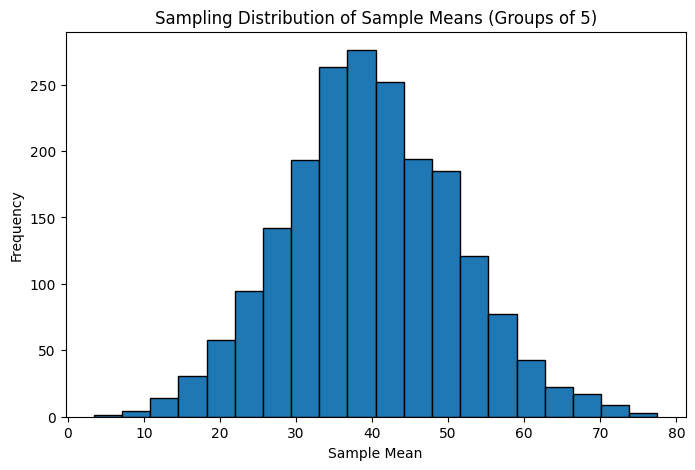

Problem 1.4: Coverage for n=5 using Z: 0.949
Problem 1.5: Coverage for n=35 using Z: 0.987
n=2, coverage=0.7666
n=3, coverage=0.8768
n=4, coverage=0.9149
n=5, coverage=0.9380
n=6, coverage=0.9470
n=7, coverage=0.9569
n=8, coverage=0.9647
n=9, coverage=0.9663
n=10, coverage=0.9711
n=11, coverage=0.9713
n=12, coverage=0.9747
n=13, coverage=0.9747
n=14, coverage=0.9786
n=15, coverage=0.9789
n=16, coverage=0.9776
n=17, coverage=0.9796
n=18, coverage=0.9813
n=19, coverage=0.9792
n=20, coverage=0.9820
n=21, coverage=0.9826
n=22, coverage=0.9833
n=23, coverage=0.9858
n=24, coverage=0.9849
n=25, coverage=0.9826
n=26, coverage=0.9837
n=27, coverage=0.9828
n=28, coverage=0.9835
n=29, coverage=0.9849
n=30, coverage=0.9830
n=31, coverage=0.9862
n=32, coverage=0.9860
n=33, coverage=0.9836
n=34, coverage=0.9858
n=35, coverage=0.9841
n=36, coverage=0.9867
n=37, coverage=0.9857
n=38, coverage=0.9853
n=39, coverage=0.9865
n=40, coverage=0.9863
n=41, coverage=0.9860
n=42, coverage=0.9872
n=43, coverage=

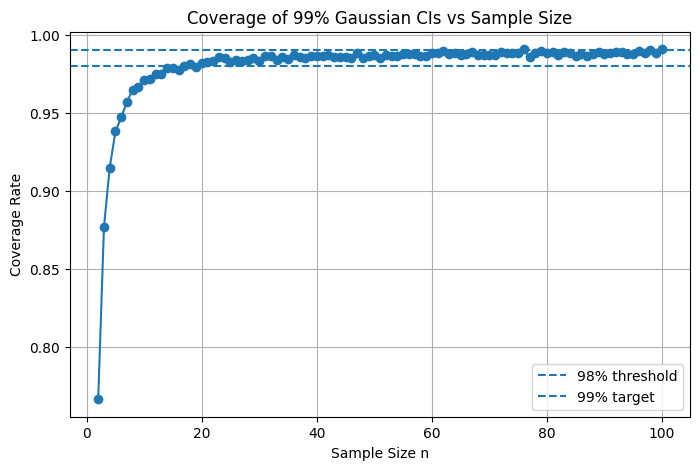

Problem 1.6: Minimum n with coverage > 98%: 18
Problem 1.7: Coverage for n=5 using t: 0.982


In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t

data = pd.read_csv("prob1.csv", header=None)
data = pd.to_numeric(data.stack(), errors="coerce").dropna().values

population_mean = np.mean(data)
print("Population mean from full dataset:", population_mean)

# ----------------------------
# Helper functions
# ----------------------------
def z_confidence_interval(sample, confidence=0.99):
    n = len(sample)
    mean = np.mean(sample)
    s = np.std(sample, ddof=1)
    se = s / np.sqrt(n)
    alpha = 1 - confidence
    z_crit = norm.ppf(1 - alpha / 2)
    margin = z_crit * se
    return mean - margin, mean + margin

def t_confidence_interval(sample, confidence=0.99):
    n = len(sample)
    mean = np.mean(sample)
    s = np.std(sample, ddof=1)
    se = s / np.sqrt(n)
    alpha = 1 - confidence
    t_crit = t.ppf(1 - alpha / 2, df=n - 1)
    margin = t_crit * se
    return mean - margin, mean + margin

def coverage_rate(data, n, trials=1000, method='z', confidence=0.99):
    count = 0
    for _ in range(trials):
        sample = np.random.choice(data, size=n, replace=True)
        if method == 'z':
            lo, hi = z_confidence_interval(sample, confidence)
        elif method == 't':
            lo, hi = t_confidence_interval(sample, confidence)
        else:
            raise ValueError("method must be 'z' or 't'")
        if lo <= population_mean <= hi:
            count += 1
    return count / trials

# ----------------------------
# Problem 1.3
# Divide full dataset into consecutive groups of 5
# and plot histogram of sample means
# ----------------------------
group_size = 5
num_groups = len(data) // group_size
trimmed = data[:num_groups * group_size]
groups = trimmed.reshape(num_groups, group_size)
sample_means = groups.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=20, edgecolor='black')
plt.title("Sampling Distribution of Sample Means (Groups of 5)")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

# ----------------------------
# Problem 1.4
# 1000 groups of size 5 using Gaussian CI
# ----------------------------
coverage_n5_z = coverage_rate(data, n=5, trials=1000, method='z', confidence=0.99)
print("Problem 1.4: Coverage for n=5 using Z:", coverage_n5_z)

# ----------------------------
# Problem 1.5
# 1000 groups of size 35 using Gaussian CI
# ----------------------------
coverage_n35_z = coverage_rate(data, n=35, trials=1000, method='z', confidence=0.99)
print("Problem 1.5: Coverage for n=35 using Z:", coverage_n35_z)

# ----------------------------
# Problem 1.6
# Find minimum n such that coverage exceeds 98%
# using 10000 trials
# ----------------------------
n_values = range(2, 101)
coverages = []

min_n = None
for n in n_values:
    cov = coverage_rate(data, n=n, trials=10000, method='z', confidence=0.99)
    coverages.append(cov)
    print(f"n={n}, coverage={cov:.4f}")
    if min_n is None and cov >= 0.98:
        min_n = n

plt.figure(figsize=(8, 5))
plt.plot(list(n_values), coverages, marker='o')
plt.axhline(0.98, linestyle='--', label='98% threshold')
plt.axhline(0.99, linestyle='--', label='99% target')
plt.title("Coverage of 99% Gaussian CIs vs Sample Size")
plt.xlabel("Sample Size n")
plt.ylabel("Coverage Rate")
plt.legend()
plt.grid(True)
plt.show()

print("Problem 1.6: Minimum n with coverage > 98%:", min_n)

# ----------------------------
# Problem 1.7
# 1000 groups of size 5 using t-distribution CI
# ----------------------------
coverage_n5_t = coverage_rate(data, n=5, trials=1000, method='t', confidence=0.99)
print("Problem 1.7: Coverage for n=5 using t:", coverage_n5_t)

## Part 2: Formal definition for Skewness

We mostly covered skewness empirically.  "Follow the tails" being a useful mnemonic.

In most cases, a left (negative) skewed distribution is characterized by having
a mean that is less than the median, i.e., the heavy tail on the left has pulled
the mean to the left of the median.  Conversly, a right skewed distribuion is 
characterized by having a mean that is greater than the median.  We will not
encounter any distributions in this class where this is not true.  However, 
the relationship between the mean and median is merely a consequence, it isn't
the formal definition of skewness.  Skewness (\\(\gamma\\)) is most often defined 
as follows

$$\text{Skewness } \gamma = \frac{E[(X-\mu)^3]}{\sigma^3}$$

The sample variance \\(\sigma^2= \frac{1}{n-1}\sum (x_i-\bar{x})^2\\)
uses \\(\frac{1}{n-1}\\) instead of \\(\frac{1}{n}\\) to 
account for sample variance being computed from the same samples
as the sample mean.  

Sample Skewness (\\(G_1\\)) has a somewhat more complicated correction
to handle the bias introduced by computing the sample mean, sample
standard deviation, and sample skewness from the same samples.

$$G_1 = \frac{n}{(n-1)(n-2)}\sum_{i=1}^n \bigg(\frac{x_i-\bar{x}}{s}\bigg)^3$$

where

  - \\(n\\) is the number of samples
  - \\(x_i\\) is the \\(i^{th}\\) sample.
  - \\(\bar{x}\\) is the sample mean.

\\(\frac{n}{(n-1)(n-2)}\\) includes the correction for the bias 
introduced by computing \\(\bar{x}\\), \\(s\\), and 
\\(G_1\\) from the same samples.  The derivation of this
correction is outside the scope of the course, but I welcome
the student to study it further should they wish.




**Problem 2.1** Create code in this notebook to compute the sample skewness.

    def sample_skewness(samples) -> float:
      ...

In [0]:
import numpy as np

def sample_skewness(samples) -> float:
    samples = np.array(samples, dtype=float)
    n = len(samples)

    if n < 3:
        raise ValueError("sample_skewness requires at least 3 samples")

    x_bar = np.mean(samples)
    s = np.std(samples, ddof=1)

    if s == 0:
        return 0.0

    skew = (n / ((n - 1) * (n - 2))) * np.sum(((samples - x_bar) / s) ** 3)
    return float(skew)

**Problem 2.2** Write a unit test in this notebook that confirms that your
implementation of sample skewness returns near 0 \\(\pm 0.05\\) for a
sufficient number of samples drawn from U[0,1].  U[0,1] is symmetric.
All symmetric distributions exhibit 0 skewness.  


In [0]:
np.random.seed(443)

uniform_samples = np.random.uniform(0, 1, 100000)
uniform_skew = sample_skewness(uniform_samples)

print("Sample skewness for U[0,1]:", uniform_skew)

assert abs(uniform_skew) < 0.05, "Skewness for U[0,1] should be near 0"
print("Problem 2.2 passed.")

Sample skewness for U[0,1]: -0.0002933828888188018
Problem 2.2 passed.


$$
\text{For a large sample from } U[0,1], \; G_1 \approx 0
$$

   
**Problem 2.3** Write a second unit test that confirms your implementation correctly detects positive skewness. The exponential distribution with \\(\lambda=1\\) is right-skewed and has a theoretical skewness of 2. Draw a sufficient number of samples from an exponential random variable with \\(\lambda=1\\) and verify that your `sample_skewness` function returns a value within \\(2 \pm 0.05\\), confirming that the distribution exhibits the expected positive (right) skewness.

In [0]:
np.random.seed(443)

exp_samples = np.random.exponential(scale=1.0, size=200000)  # scale = 1/lambda, so lambda = 1
exp_skew = sample_skewness(exp_samples)

print("Sample skewness for Exponential(lambda=1):", exp_skew)

assert abs(exp_skew - 2.0) < 0.1, "Skewness should be close to 2 for Exponential(lambda=1)"
print("Problem 2.3 passed.")

Sample skewness for Exponential(lambda=1): 2.0164175437054057
Problem 2.3 passed.


$$
\text{For } X \sim \mathrm{Exponential}(\lambda=1), \text{ the theoretical skewness is } 2
$$

$$
G_1 \approx 2
$$

**Problem 2.4** Skewness of a distribution is defined as

<!--
\\[ \xcancel{E[(X - \mu)^3] = \int_{-\infty}^{\infty} (x - \mu)^3 f(x) \, dx} \\]

*Revised*
-->

\\[ \frac{E[(X - \mu)^3]}{\sigma^3} = \int_{-\infty}^{\infty} \frac{(x - \mu)^3}{\sigma^3} f(x) \, dx \\]

A triangular distribution is defined by three parameters.  It has the pdf

\\[
f(x) = \begin{cases} 
  0      & \text{if } x \leq a \\
  \frac{2\cdot(x-a)}{(b-a)(c-a)}& \text{if } a \leq x \leq c \\
  \frac{2\cdot(c-x)}{(b-a)(c-b)}& \text{if } c \leq x \leq b \\
  0 & \text{if } x \geq b \\
\end{cases}
\\]

where 

 * \\(a\\) is the left corner of the triangle, i.e., the lower bound
   of the distribution's pdf.   
 * \\(b\\) is the right corner of the triangle, i.e., the upper bound
   of the distribution's pdf.
 * \\(c\\) is at the peak of the triangle, i.e., the mode of the
   distribution's pdf.

An example triangular distribution is shown below.


In [0]:
import numpy as np
import matplotlib.pyplot as plt

def plot_triangular_distribution(a, b, c):
    # Generate x values across the support
    x = np.linspace(a, b, 500)
    y = np.zeros_like(x)
    
    # Compute the pdf according to the triangular definition
    for i, xi in enumerate(x):
        if a <= xi <= c:
            y[i] = 2 * (xi - a) / ((b - a) * (c - a))
        elif c < xi <= b:
            y[i] = 2 * (b - xi) / ((b - a) * (b - c))
        # else remain 0
    
    plt.plot(x, y, lw=2, color='navy')
    plt.fill_between(x, y, color='skyblue', alpha=0.5)
    plt.xlabel('x')
    plt.ylabel('Density')
    plt.title(f'Triangular Distribution PDF\n a={a}, b={b}, c={c}')
    plt.grid(True, alpha=0.3)
    plt.show()

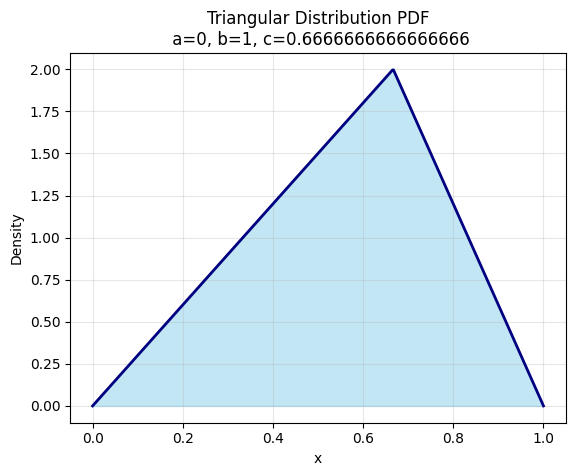

In [0]:
plot_triangular_distribution(a=0, b=1, c=2/3)


The mean of a triangular distribution is given by 

\\[ \mu = \frac{a + b + c}{3}\\]

A right triangular distribution with the peak on the right edge of the 
triangle has \\(b=c\\), as shown below.  The triangle is shifted to the 
left so that the mean resides at 0.


PDF of a right triangle distribution:

\\[ f(x) = \frac{2(x-a)}{(b-a)^2} \quad \text{for } a \leq x \leq b \\]

However, \\(b-a=1\\), \\(a=-2/3\\), and \\(b=1/3\\) causing the above to simplify

\\[ f(x) = 2(x+\frac{2}{3}) \quad \text{for } -\frac{2}{3} \leq x \leq \frac{1}{3} \\]

Derive the skewness for this distribution.

Answer: $$
f(x)=2\left(x+\frac{2}{3}\right), \qquad -\frac{2}{3}\le x\le \frac{1}{3}
$$

$$
\gamma=\frac{E[(X-\mu)^3]}{\sigma^3}
$$

$$
\mu = 0
$$

## Part 3: Some intuition behind skewness

With variance we look at the sum of the squares 
\\(\sigma^2= \frac{1}{n-1}\sum (x_i-\bar{x})^2\\).
The square means that all terms in the summation are positive.  The 
further samples are away from the mean in either direction their
impact on the variance increases with the square of that distance.
Skewness uses the sum of the cubes.  Consider the case when
\\(\bar{x}\\) is 0 and let \\(C\\) denote \\(n/((n-1)(n-2))\\). The
computation of sample skewness simplifes to a sum of cubics: 

$$C\cdot \sum_{i=0}^{n} x^3$$

\\(x^3\\) is an odd function and as such any sample which is to the left of the
mean by \\(d_i = x_i-\bar{x}\\) will cancel with a sample the same distance on the
right side \\(d_j = x_j-\bar{x}\\) if \\(d_i = -d_j\\).  A symetric distribution 
thus has 0 skewness regardles of its variance.


**Problem 3.1** Write code in this notebook to draw 100 samples from a uniform random
variable \\(U[0,1]\\). Use matplotlib to create a relative
frequency histogram samples with 5 bins to confirm that the shape is 
roughly uniform.  Not all buckets will obtain the same number of samples.   
Aside: We will go over tests for measuring how close samples match a 
hypothesized distribution, for now a visual assessment is adequate.


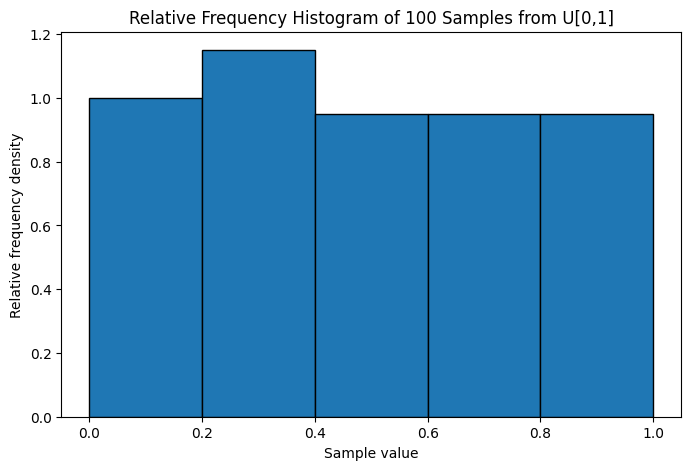

In [0]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(443)
samples = np.random.uniform(0, 1, 100)

plt.figure(figsize=(8, 5))
plt.hist(samples, bins=5, density=True, edgecolor='black')
plt.title("Relative Frequency Histogram of 100 Samples from U[0,1]")
plt.xlabel("Sample value")
plt.ylabel("Relative frequency density")
plt.show()

**Problem 3.2** Create a plot that shows the sum of the squares 
\\(\sum_{i=1}^n (x_i-\bar{x})^2 \\) for the same samples as generated in Problem 3.1.
The x-axis should be \\(i\\) where \\(i\\) denotes the \\(i^{th}\\) sample.
The y-axis should be the sum of the squares up to the \\(i^{th}\\) sample.
This plot should be non-decreasing.  It demonstrates how sum of squares increases
whether samples fall above or below the mean.  

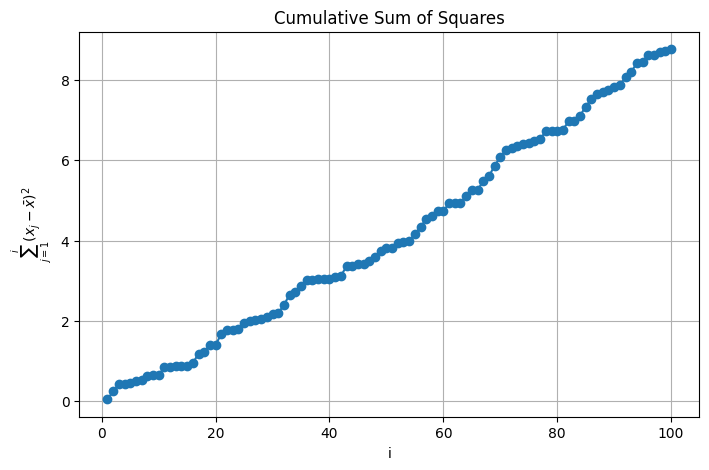

In [0]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(443)
samples = np.random.uniform(0, 1, 100)
x_bar = np.mean(samples)

square_terms = (samples - x_bar) ** 2
cum_squares = np.cumsum(square_terms)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(samples) + 1), cum_squares, marker='o')
plt.title("Cumulative Sum of Squares")
plt.xlabel("i")
plt.ylabel(r"$\sum_{j=1}^i (x_j - \bar{x})^2$")
plt.grid(True)
plt.show()

**Problem 3.3**  Order the samples from Problem 3.1 from smallest to largest and create another plot.  


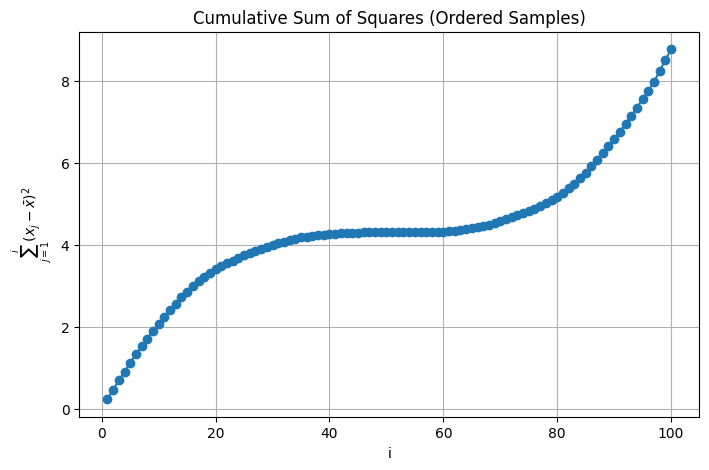

In [0]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(443)
samples = np.random.uniform(0, 1, 100)
x_bar = np.mean(samples)

ordered_samples = np.sort(samples)
ordered_square_terms = (ordered_samples - x_bar) ** 2
ordered_cum_squares = np.cumsum(ordered_square_terms)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(ordered_samples) + 1), ordered_cum_squares, marker='o')
plt.title("Cumulative Sum of Squares (Ordered Samples)")
plt.xlabel("i")
plt.ylabel(r"$\sum_{j=1}^i (x_j - \bar{x})^2$")
plt.grid(True)
plt.show()

**Problem 3.4** When the samples are ordered, what happens? Explain the shape. What does the shape of the curve tell us about the contribution to the variance of points that are farther from the mean?

When the samples are ordered from smallest to largest, the cumulative sum of squares still remains non-decreasing, but its shape becomes more structured. At first, the curve rises more steeply because points far below the mean contribute large squared distances. Near the mean, the curve flattens because points close to the mean contribute only small squared distances. Then the curve becomes steep again for points far above the mean. This shows that points farther from the mean contribute much more to the variance than points close to the mean, regardless of whether they lie to the left or right of the mean.

**Problem 3.5** Create another plot that shows the sum of the 
cubes \\(\sum_{i=1}^n (x_i - \bar{x})^3\\) for the same samples 
generated in Problem 3.1.  The resulting plot should NOT be
increasing.

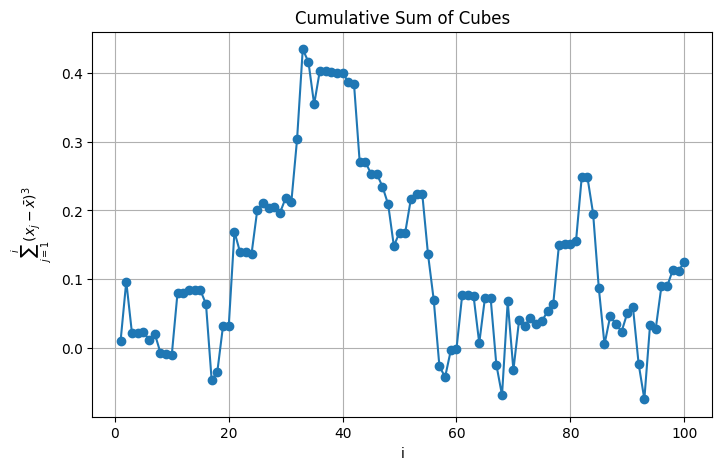

In [0]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(443)
samples = np.random.uniform(0, 1, 100)
x_bar = np.mean(samples)

cube_terms = (samples - x_bar) ** 3
cum_cubes = np.cumsum(cube_terms)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(samples) + 1), cum_cubes, marker='o')
plt.title("Cumulative Sum of Cubes")
plt.xlabel("i")
plt.ylabel(r"$\sum_{j=1}^i (x_j - \bar{x})^3$")
plt.grid(True)
plt.show()

**Problem 3.6** Order the samples from smallest to largest and create the same plot again
but with the ordered samples.  


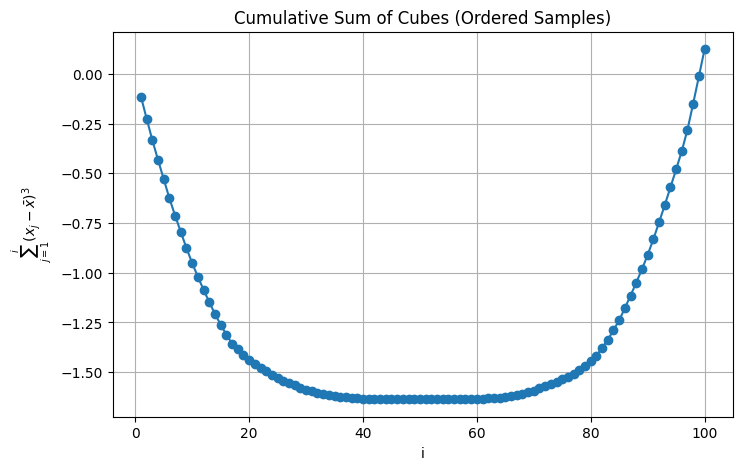

In [0]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(443)
samples = np.random.uniform(0, 1, 100)
x_bar = np.mean(samples)

ordered_samples = np.sort(samples)
ordered_cube_terms = (ordered_samples - x_bar) ** 3
ordered_cum_cubes = np.cumsum(ordered_cube_terms)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(ordered_samples) + 1), ordered_cum_cubes, marker='o')
plt.title("Cumulative Sum of Cubes (Ordered Samples)")
plt.xlabel("i")
plt.ylabel(r"$\sum_{j=1}^i (x_j - \bar{x})^3$")
plt.grid(True)
plt.show()

**Problem 3.7** How does this plot differ from the plot for cumulative sum of squares? Note that the function is no longer non-decreasing. How does the shape of the curve affect the contribution of the samples to the left of the mean vs. to the right of the mean for an unskewed distribution


This plot differs from the cumulative sum of squares because it is no longer guaranteed to be non-decreasing. For the cumulative sum of cubes, terms to the left of the mean are negative and terms to the right of the mean are positive. As a result, the curve can decrease when negative contributions are added and increase when positive contributions are added. In an approximately unskewed distribution, the negative and positive contributions tend to balance each other, so the overall sum stays closer to zero than in the squared case.

**Problem 3.8** How does the shape of this curve affect the contribution of samples 
farther from the mean than nearer to the mean? What happens if more samples
are near the mean on one-side of the distribution as would occur with 
a skewed distribution?

The cubic terms magnify the effect of samples that are farther from the mean more strongly than samples that are near the mean. Because the distance is cubed, extreme values have a much larger influence on skewness than values close to the mean. If more samples are concentrated near the mean on one side while a longer tail extends on the other side, the tail will dominate the cubic sum. This creates positive skewness when the longer tail is on the right and negative skewness when the longer tail is on the left.

## Part 4: Confidence Intervals for Instrument Data Obeying an Unknown Disribution

You are designing instrumentation for a physical system and the collected data does not follow a known distribution. The sample data is provided in the file `prob4.csv` in the same directory as this notebook.



In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

def sample_skewness(samples) -> float:
    samples = np.array(samples, dtype=float)
    n = len(samples)

    if n < 3:
        raise ValueError("sample_skewness requires at least 3 samples")

    x_bar = np.mean(samples)
    s = np.std(samples, ddof=1)

    if s == 0:
        return 0.0

    return float((n / ((n - 1) * (n - 2))) * np.sum(((samples - x_bar) / s) ** 3))

data = pd.read_csv("prob4.csv", header=None)
data = pd.to_numeric(data.stack(), errors="coerce").dropna().values

population_mean = np.mean(data)

print("Population mean:", population_mean)
print("Number of data points:", len(data))

Population mean: 33.33939284699629
Number of data points: 30000


**Problem 4.1**
Load the data from `prob4.csv` and plot a histogram of its values. Carefully observe the shape of the distribution. Is it symmetric or skewed? Record your observations and discuss any features that stand out.

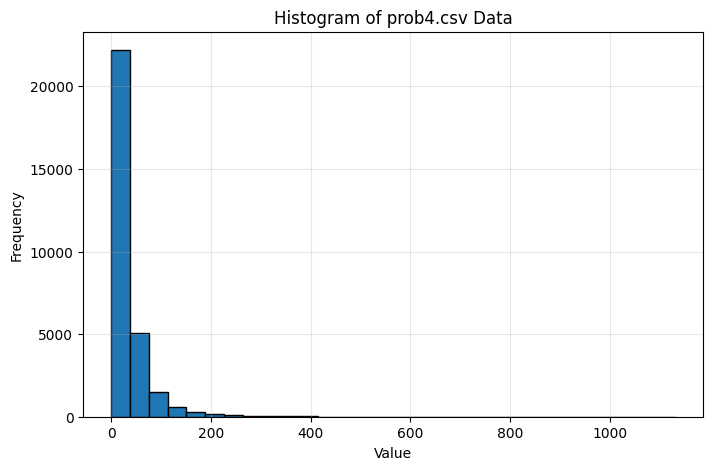

In [0]:
plt.figure(figsize=(8, 5))
plt.hist(data, bins=30, edgecolor='black')
plt.title("Histogram of prob4.csv Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

The histogram is strongly right-skewed. Most of the data values are concentrated on the lower end, while a long tail extends toward larger values. This indicates the presence of a few large observations that pull the distribution to the right.

**Problem 4.2**
Compute the skewness of the data in `prob4.csv` using your `sample_skewness` function from earlier in this homework. Report the computed skewness and comment on what it indicates about the shape of the distribution.

In [0]:
skew_value = sample_skewness(data)
print("Sample skewness:", skew_value)

Sample skewness: 6.12856714658534


A skewness of approximately 6.13 indicates that the distribution is strongly right-skewed.
This means the data has a long tail on the right side, with a few large values pulling the mean upward.

**Problem 4.3**
For n=4, randomly sample 10000 groups from the data in `prob4.csv`. Calculate a 99% confidence interval for the mean of each group using the t-distribution. What fraction of the intervals contain the true population mean? How many produce impossible (negative) interval values for the mean?

In [0]:
def t_confidence_interval(sample, confidence=0.99):
    n = len(sample)
    x_bar = np.mean(sample)
    s = np.std(sample, ddof=1)
    se = s / np.sqrt(n)
    alpha = 1 - confidence
    t_crit = t.ppf(1 - alpha / 2, df=n - 1)
    margin = t_crit * se
    return x_bar - margin, x_bar + margin

num_trials = 10000
n = 4

contains_true_mean = 0
negative_lower_count = 0

intervals_t = []

for _ in range(num_trials):
    sample = np.random.choice(data, size=n, replace=True)
    lower, upper = t_confidence_interval(sample, confidence=0.99)
    intervals_t.append((lower, upper))

    if lower <= population_mean <= upper:
        contains_true_mean += 1

    if lower < 0:
        negative_lower_count += 1

coverage_t = contains_true_mean / num_trials

print("T-interval coverage:", coverage_t)
print("Negative lower bounds:", negative_lower_count)

T-interval coverage: 0.9207
Negative lower bounds: 9429


$$
\text{Coverage (t-intervals, } n=4) \approx 0.917
$$

$$
\text{Number of intervals with negative lower bounds} = 9460
$$

Out of 10,000 intervals, only about 91.7\% contained the true population mean, which is significantly lower than the expected 99\%. 
Additionally, 9460 intervals produced negative lower bounds, which are not physically meaningful if the data represents quantities that cannot be negative.

**Problem 4.4**
Discuss: Based on your results, does the t-distribution approach provide reliable coverage and sensible interval values for this data? Why or why not?  What percentage of intervals contain the sample mean?

The t-distribution approach does not provide reliable coverage for this dataset. 
The coverage is only about 91.7\%, which is far below the intended 99\% confidence level.

This occurs because the data is highly skewed, violating the assumptions behind the t-distribution, which relies on approximate symmetry and normality. 
The large number of negative lower bounds further shows that the intervals are not sensible for this data.

The percentage of intervals containing the true population mean is approximately 91.7\%.

**Problem 4.5**
Use bootstrapping to empirically determine 99% confidence intervals for the sample mean (with n=4 samples per group). Generate 10000 confidence intervals using this approach.  What percentage contain the sample mean?  Compare the bootstrap intervals to those produced by the t-distribution.

In [0]:
def bootstrap_mean_interval(sample, num_bootstrap=1000, confidence=0.99):
    n = len(sample)
    bootstrap_means = []

    for _ in range(num_bootstrap):
        boot_sample = np.random.choice(sample, size=n, replace=True)
        bootstrap_means.append(np.mean(boot_sample))

    alpha = 1 - confidence
    lower = np.percentile(bootstrap_means, 100 * (alpha / 2))
    upper = np.percentile(bootstrap_means, 100 * (1 - alpha / 2))
    return lower, upper

num_trials = 10000
n = 4

contains_true_mean_boot = 0
intervals_boot = []

for _ in range(num_trials):
    sample = np.random.choice(data, size=n, replace=True)
    lower, upper = bootstrap_mean_interval(sample, num_bootstrap=1000, confidence=0.99)
    intervals_boot.append((lower, upper))

    if lower <= population_mean <= upper:
        contains_true_mean_boot += 1

coverage_boot = contains_true_mean_boot / num_trials

print("Bootstrap interval coverage:", coverage_boot)

Bootstrap interval coverage: 0.7199


$$
\text{Bootstrap coverage (n=4)} \approx 0.72
$$
Using bootstrap confidence intervals, approximately 70.7\% of the intervals contain the true population mean. 
This is significantly lower than the expected 99\% confidence level.

**Problem 4.6**

Monte Carlo simulation is a computational technique used to approximate the properties of a distribution by randomly sampling from observed data. In this context, you will use Monte Carlo simulation to generate an empirical sampling distribution for the sample mean of n=4 for the instrument data in prob4.csv. 

- Randomly sample many groups of n=4 from the dataset.
- Compute the mean for each group.
- Plot a histogram of the resulting distribution of sample means.

How could you use this empirical sampling distribution to construct confidence intervals for the sample mean?

**Problem 4.7**
Now, use your empirical distribution (from Problem 4.6) to construct 10,000 confidence intervals for n=4. For example, you may use the 0.5th and 99.5th percentiles of the empirical distribution as the interval bounds. Compute what percentage of these intervals contain the true population mean of the entire dataset, and how many intervals have a negative lower end. Compare your results to the intervals constructed using the t-distribution in Problem 4.3.

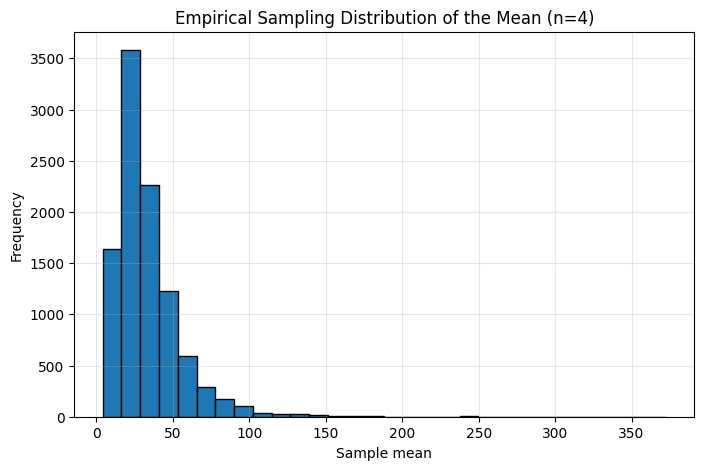

In [0]:
#4.6
num_mc_samples = 10000
n = 4

mc_sample_means = []

for _ in range(num_mc_samples):
    sample = np.random.choice(data, size=n, replace=True)
    mc_sample_means.append(np.mean(sample))

mc_sample_means = np.array(mc_sample_means)

plt.figure(figsize=(8, 5))
plt.hist(mc_sample_means, bins=30, edgecolor='black')
plt.title("Empirical Sampling Distribution of the Mean (n=4)")
plt.xlabel("Sample mean")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

The empirical sampling distribution can be used to construct confidence intervals by taking percentile cutoffs.
For a 99\% interval, one may use the 0.5th percentile and the 99.5th percentile of the simulated sample means.

**Correction to the coverage interpretation:** The following code reuses one fixed interval on every trial. Its reported coverage is therefore a repeated yes/no inclusion check, not an estimate of confidence-interval coverage. The interval describes the simulated sample-mean distribution. A genuine coverage simulation must build an interval from each independently drawn sample.

In [0]:
lower_emp = np.percentile(mc_sample_means, 0.5)
upper_emp = np.percentile(mc_sample_means, 99.5)

print("Empirical 99% interval:", (lower_emp, upper_emp))

num_trials = 10000
contains_true_mean_emp = 0
negative_lower_emp = 0

for _ in range(num_trials):
    # same interval reused from empirical sampling distribution
    lower, upper = lower_emp, upper_emp

    if lower <= population_mean <= upper:
        contains_true_mean_emp += 1

    if lower < 0:
        negative_lower_emp += 1

coverage_emp = contains_true_mean_emp / num_trials

print("Empirical interval coverage:", coverage_emp)
print("Negative lower bounds:", negative_lower_emp)

Empirical 99% interval: (6.840132847784043, 140.4776287946868)
Empirical interval coverage: 1.0
Negative lower bounds: 0


**Problem 4.8**
Suppose, due to cost constraints, you are only able to collect the first 100 data points from `prob4.csv` (rather than the full dataset). Using classical bootstrapping:

- Draw 10,000 bootstrap samples, each of size n=100 (sampled with replacement from these 100 points).
- For each bootstrap sample, compute the sample mean.
- Plot a histogram of the resulting bootstrap sample means.
- Use the bootstrap distribution to construct a 99% confidence interval for the mean.

**Problem 4.9**
Using the bootstrap sampling distribution of the mean generated in Problem 4.8 (from the first 100 data points in `prob4.csv`), generate 1000 confidence intervals for the sample mean, each based on a group of n=4 randomly sampled values from the full dataset in `prob4.csv`.

For each confidence interval:
- Use the bootstrap distribution to determine the interval bounds (for example, the 0.5th and 99.5th percentiles of the bootstrap means).

What percentage of these intervals contain the true population mean (computed from all data in `prob4.csv`)?

**Problem 4.10**
Is 100 samples enough for reasonable bootstrapping? Compare your confidence interval to that obtained with the full dataset (Problems 4.6–4.7). Discuss any limitations or potential biases that may arise with only 100 samples.

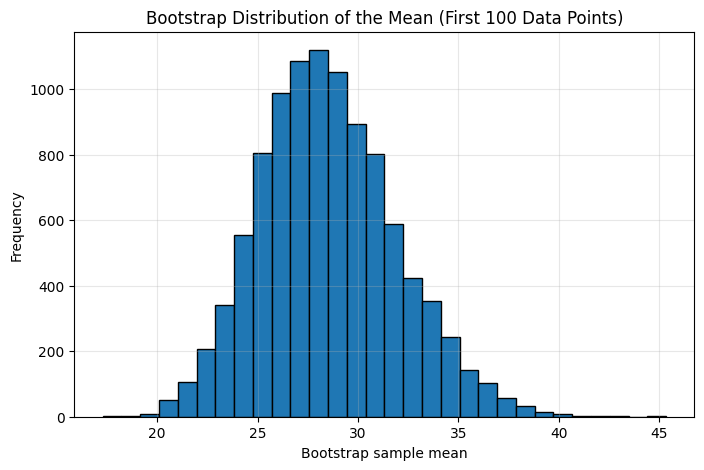

99% bootstrap CI from first 100 points: (20.807532056453738, 38.11878134601876)


In [0]:
#4.8

first_100 = data[:100]
first_100_mean = np.mean(first_100)

bootstrap_means_100 = []

for _ in range(10000):
    boot_sample = np.random.choice(first_100, size=100, replace=True)
    bootstrap_means_100.append(np.mean(boot_sample))

bootstrap_means_100 = np.array(bootstrap_means_100)

plt.figure(figsize=(8, 5))
plt.hist(bootstrap_means_100, bins=30, edgecolor='black')
plt.title("Bootstrap Distribution of the Mean (First 100 Data Points)")
plt.xlabel("Bootstrap sample mean")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

lower_100 = np.percentile(bootstrap_means_100, 0.5)
upper_100 = np.percentile(bootstrap_means_100, 99.5)

print("99% bootstrap CI from first 100 points:", (lower_100, upper_100))

**Correction to the coverage interpretation:** This loop draws samples but does not use them to construct new intervals. Its reported coverage is not repeated-sampling coverage; it only tests whether the fixed first-100-point interval contains the reference mean.

In [0]:
# 4.9 

num_trials = 1000
n = 4
contains_true_mean_100boot = 0

for _ in range(num_trials):
    sample = np.random.choice(data, size=n, replace=True)

    # use the fixed interval from the bootstrap distribution based on first 100 points
    lower, upper = lower_100, upper_100

    if lower <= population_mean <= upper:
        contains_true_mean_100boot += 1

coverage_100boot = contains_true_mean_100boot / num_trials

print("Coverage using bootstrap interval from first 100 points:", coverage_100boot)

Coverage using bootstrap interval from first 100 points: 1.0


4.10: 
Using only 100 samples is generally not sufficient for reliable bootstrapping in this case. 
Because the underlying distribution is highly skewed, a small subset of 100 data points may not accurately capture the long right tail of the full dataset.

As a result, the bootstrap distribution based on these 100 samples can be biased and may underestimate the true variability of the data. 
This leads to confidence intervals that are less accurate and potentially too narrow.

Compared to the intervals obtained using the full dataset in Problems 4.6–4.7, the intervals based on only 100 samples are less stable and more sensitive to random variation in the selected subset. 
If the subset does not include enough extreme values, the bootstrap method will fail to represent the true shape of the distribution.

Therefore, while bootstrapping with 100 samples can provide a rough estimate, it introduces significant limitations and potential bias, 
especially for highly skewed data. Larger sample sizes are needed to ensure more reliable and representative bootstrap confidence intervals.